# G110 - YOLOv8x-P2 (Ultralytics): people on land vs in water (same outputs as all 5 team models)
**Dataset:** Roboflow *G110 Beach People Final* - version set in the settings cell (`RF_VERSION`). Download format: **YOLOv8**.
**Classes:** 0 = person on land, 1 = person in water. People shorter than 15 px are ignored in evaluation (same rule for all 5 models).
**Outputs (one zip):** training curves, mAP@50 / mAP@50:95 / precision / recall / F1, per class, per beach, confusion matrices (overall + per beach),
PR curves, crowd levels, technique comparison (with / without: denoise, CLAHE, NMS, TTA, transfer learning, threshold), per-frame land/water counts,
GT-vs-prediction video per test clip, continuous real-speed video per test clip.
**Before running:** Settings -> Accelerator = **GPU T4 x2**, Internet = **ON**. Add Input -> dataset **g110-test-videos** (videos + waterlines.json).
Paste your Roboflow download code (format **YOLOv8**, version = RF_VERSION) in a NEW cell at the very top, then Save Version -> Save & Run All.
**This run:** dataset **v2**, 1280 px, both T4 GPUs, training time fixed at 8.5 h: Ultralytics sets the number of epochs itself so that training ends at 8.5 h (the learning-rate schedule is fitted to that), and the best epoch on validation is kept. Early stop if validation does not improve for 15 epochs.

In [1]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="PASTE_YOUR_ROBOFLOW_KEY_HERE")
project = rf.workspace("mbalajis-workspace-g2gae").project("g110-beach-people-final")
version = project.version(2)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 80.6 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [roboflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to G110-Beach-People-Final-2 in yolov8:: 100%|██████████| 9275/9275 [00:02<00:00, 4171.42it/s]


In [2]:
import os, sys, subprocess, json, glob, csv, math, shutil, zipfile, collections, random, time, re, io, contextlib
subprocess.run([sys.executable, '-m', 'pip', 'install', 'ultralytics', 'roboflow', 'pycocotools', 'seaborn', '-q'])
import numpy as np, cv2, torch, yaml
print('torch', torch.__version__, '| GPU:', torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else '')
import ultralytics; print('ultralytics', ultralytics.__version__)

torch 2.11.0+cu130 | GPU: True Tesla T4
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
ultralytics 8.4.212


In [3]:
# ---------------- settings you may edit ----------------
MODEL_KIND = 'yolov8x-p2'      # 'yolov8x-p2' or 'rtdetr-l'
IMGSZ = 1280             # NOT 640: the swimmers are small
EPOCHS = 100             # starting value only: because TRAIN_HOURS is set, Ultralytics replaces it with the number of epochs that fit in TRAIN_HOURS
TRAIN_HOURS = 8.5        # Kaggle sessions stop at 12 h - leave ~3 h for the evaluation part below
BATCH_PER_GPU = 2        # 2 fits a T4 (16 GB) at 1280 px; lower to 1 if you see 'CUDA out of memory'
N_GPU = torch.cuda.device_count(); print('GPUs:', N_GPU)   # Kaggle 'GPU T4 x2' -> 2 GPUs -> about 2x faster
PATIENCE = 15
SCORE_THR = 0.5          # replaced below by the threshold chosen on the VALIDATION split
IOU_THR = 0.5
VIDEO_FPS = 3            # frames were sampled every 3 s, so 3 fps plays them 9x faster than real time
OUT = '/kaggle/working/outputs'; os.makedirs(OUT, exist_ok=True)
NAMES = ['land', 'water']
MIN_H = 15               # people shorter than this (pixels) are ignored in evaluation - same rule for all 5 models
RF_WORKSPACE, RF_PROJECT, RF_VERSION = 'mbalajis-workspace-g2gae', 'g110-beach-people-final', 2   # use the version the team agreed on
CONT_SECONDS = 60        # continuous video: first N seconds of each test clip at real speed
CONT_STRIDE = 2          # run the model every 2nd video frame and keep the boxes in between
MASKS = {'whitebay': [(1690, 0, 230, 290), (0, 1000, 1920, 80)]}   # same black boxes as the training frames (QR code + banner)

GPUs: 2


In [4]:
# ---------------- dataset: Roboflow YOLOv8 export -> fixed data.yaml + COCO json for evaluation ----------------
Y = None
try:                                                                   # 1st choice: ROBOFLOW_API_KEY secret
    from kaggle_secrets import UserSecretsClient
    from roboflow import Roboflow
    key = UserSecretsClient().get_secret('ROBOFLOW_API_KEY')
    Y = Roboflow(api_key=key).workspace(RF_WORKSPACE).project(RF_PROJECT).version(RF_VERSION).download('yolov8', location=f'/kaggle/working/rf_v{RF_VERSION}').location
except Exception as e:
    print('Roboflow secret download not used:', str(e)[:120])
if Y is None:                                                          # 2nd choice: the pasted Roboflow snippet downloaded into /kaggle/working
    for dp, dn, fn in os.walk('/kaggle/working'):
        if 'data.yaml' in fn and os.path.isdir(os.path.join(dp, 'train', 'labels')): Y = dp; break
assert Y, 'YOLOv8 dataset not found - paste the Roboflow download code (format YOLOv8) in a cell at the very top and run it'
print('dataset:', Y); ROOT = Y
d = yaml.safe_load(open(os.path.join(Y, 'data.yaml'))); print('class names in data.yaml:', d.get('names'))
assert [str(n) for n in d['names']] in (['0', '1'], ['land', 'water']), 'unexpected class names'
d.update(path=Y, train='train/images', val='valid/images', test='test/images'); DATA_YAML = os.path.join(Y, 'data_fixed.yaml'); yaml.safe_dump(d, open(DATA_YAML, 'w'))
def to_coco(split):
    idir, ldir = os.path.join(Y, split, 'images'), os.path.join(Y, split, 'labels'); ims, anns = [], []
    for i, f in enumerate(sorted(os.listdir(idir))):
        p = os.path.join(idir, f); H_, W_ = cv2.imread(p).shape[:2]; ims.append({'id': i, 'file_name': p, 'width': W_, 'height': H_})
        lp = os.path.join(ldir, os.path.splitext(f)[0] + '.txt')
        if not os.path.exists(lp): continue
        for l in open(lp):
            q = l.split()
            if len(q) != 5: continue
            c, cx, cy, w, h = int(q[0]), *map(float, q[1:]); bw, bh = w * W_, h * H_
            if bw < 1 or bh < 1: continue                                               # same filter as the Detectron2 evaluation
            anns.append({'id': len(anns) + 1, 'image_id': i, 'category_id': c, 'bbox': [(cx - w / 2) * W_, (cy - h / 2) * H_, bw, bh], 'area': bw * bh,
                         'iscrowd': 1 if (split == 'test' and bh < MIN_H) else 0})          # 15 px rule on test: ignore region
    p = f'/kaggle/working/coco_eval/{split}.json'; os.makedirs(os.path.dirname(p), exist_ok=True)
    json.dump({'images': ims, 'annotations': anns, 'categories': [{'id': 0, 'name': 'land'}, {'id': 1, 'name': 'water'}]}, open(p, 'w'))
    cc = collections.Counter(a['category_id'] for a in anns); print(f'{split:6s} images={len(ims):5d} land={cc[0]:6d} water={cc[1]:6d}'); return p
JS = {s: to_coco(s) for s in ('valid', 'test')}
test_dicts = [{'image_id': im['id'], 'file_name': im['file_name']} for im in json.load(open(JS['test']))['images']]
val_json = json.load(open(JS['valid'])); val_dicts = [{'image_id': im['id'], 'file_name': im['file_name']} for im in val_json['images']]
print('train images:', len(os.listdir(os.path.join(Y, 'train', 'images'))), '| test images:', len(test_dicts), '(expected 399)')
_ta = json.load(open(JS['test']))['annotations']; _ign = sum(a['iscrowd'] for a in _ta)
print('test boxes ignored by the 15 px rule:', _ign)
_l = sum(1 for a in _ta if not a['iscrowd'] and a['category_id'] == 0); _w = sum(1 for a in _ta if not a['iscrowd'] and a['category_id'] == 1)
print(f'test people counted: land {_l} | water {_w} | total {_l + _w}   (Detectron2 v2 evaluation had: land 4546 | water 7372 | total 11918, ignored 1296)')
if abs(_l - 4546) + abs(_w - 7372) > 30: print('WARNING: test labels differ a lot from the Detectron2 v2 evaluation - check that the Roboflow code says version(2)')
else: print('OK: same v2 test labels as Detectron2 (a difference of a few boxes is only rounding between the COCO and YOLO export formats)')

Roboflow secret download not used: Unexpected response from the service. Response: {'errors': ['No user secrets exist for kernel id 144865859 and label ROB
dataset: /kaggle/working/G110-Beach-People-Final-2
class names in data.yaml: ['0', '1']
valid  images=  782 land= 13558 water= 17885
test   images=  399 land=  4559 water=  8655
train images: 3454 | test images: 399 (expected 399)
test boxes ignored by the 15 px rule: 1296
test people counted: land 4546 | water 7372 | total 11918   (Detectron2 v2 evaluation had: land 4546 | water 7372 | total 11918, ignored 1296)
OK: same v2 test labels as Detectron2 (a difference of a few boxes is only rounding between the COCO and YOLO export formats)


In [5]:
# ---------------- TRAIN (yolov8x-p2) ----------------
from ultralytics import YOLO, RTDETR
model = YOLO('yolov8x-p2.yaml').load('yolov8x.pt')
t0 = time.time()
ARGS = dict(data=DATA_YAML, imgsz=IMGSZ, epochs=EPOCHS, time=TRAIN_HOURS, patience=PATIENCE, workers=4,
            project='/kaggle/working/runs', name='train', exist_ok=True, plots=True, seed=0)
if N_GPU >= 2:
    try:                                                    # both T4 GPUs together (DDP): ~2x more epochs in the same time
        model.train(device=[0, 1], batch=BATCH_PER_GPU * 2, **ARGS)
    except Exception as e:                                  # if 2-GPU mode fails at start, fall back to 1 GPU (nothing else changes)
        print('2-GPU training failed -> using 1 GPU:', str(e)[:200])
        left = max(0.5, TRAIN_HOURS - (time.time() - t0) / 3600); ARGS['time'] = left; print('hours left for 1-GPU training: %.1f' % left)
        model = YOLO('yolov8x-p2.yaml').load('yolov8x.pt'); model.train(device=0, batch=BATCH_PER_GPU, **ARGS)
else:
    model.train(device=0, batch=BATCH_PER_GPU, **ARGS)
RUN = '/kaggle/working/runs/train'; BEST = os.path.join(RUN, 'weights', 'best.pt')
print('training time: %.1f h | best weights:' % ((time.time() - t0) / 3600), BEST, os.path.exists(BEST))

Transferred 419/725 items from pretrained weights
Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/G110-Beach-People-Final-2/data_fixed.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1280, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/41      11.7G      1.355      1.065      1.274         74       1280: 100% ━━━━━━━━━━━━ 864/864 1.2it/s 11:51
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 98/98 3.0it/s 32.6s
                   all        782      31443      0.782      0.739      0.804      0.486

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/41      12.4G      1.312      1.002      1.236         58       1280: 100% ━━━━━━━━━━━━ 864/864 1.2it/s 11:48
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 98/98 3.0it/s 32.3s
                   all        782      31443      0.803      0.739      0.823      0.506

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/41      10.9G      1.252     0.9383      1.196        122       1280: 100% ━━━━━━━

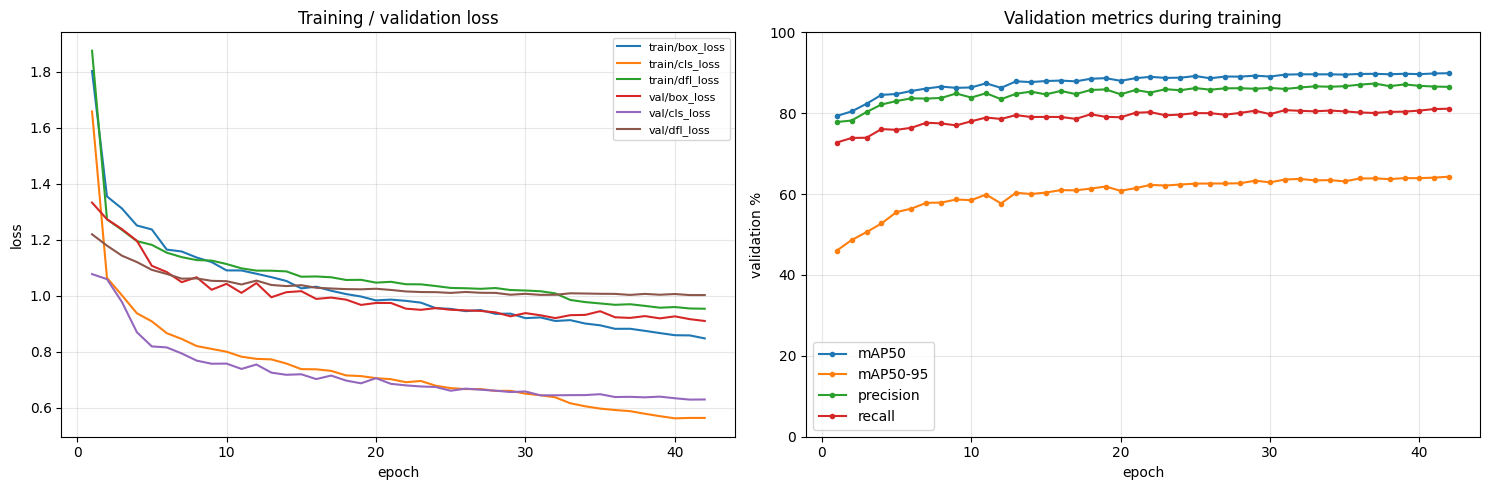

best validation mAP50: 89.90 at epoch 42
epochs trained: 42 | best epoch kept: weights/best.pt


In [6]:
# ---------------- training curves ----------------
import matplotlib.pyplot as plt
import pandas as pd
R = pd.read_csv(os.path.join(RUN, 'results.csv')); R.columns = [c.strip() for c in R.columns]
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for c in R.columns:
    if c.startswith('train/') or c.startswith('val/'): ax[0].plot(R['epoch'], R[c], label=c)
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('loss'); ax[0].set_title('Training / validation loss'); ax[0].legend(fontsize=8); ax[0].grid(alpha=.3)
for c in ('metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'metrics/precision(B)', 'metrics/recall(B)'):
    if c in R.columns: ax[1].plot(R['epoch'], 100 * R[c], marker='o', ms=3, label=c.replace('metrics/', '').replace('(B)', ''))
ax[1].set_ylim(0, 100); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation %'); ax[1].set_title('Validation metrics during training'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '01_training_curves.png'), dpi=200); plt.show()
if 'metrics/mAP50(B)' in R.columns: print('best validation mAP50: %.2f at epoch %d' % (100 * R['metrics/mAP50(B)'].max(), R.loc[R['metrics/mAP50(B)'].idxmax(), 'epoch']))
shutil.copy2(os.path.join(RUN, 'results.csv'), os.path.join(OUT, 'training_results.csv'))
if os.path.exists(os.path.join(RUN, 'args.yaml')): shutil.copy2(os.path.join(RUN, 'args.yaml'), os.path.join(OUT, 'config_used.yaml'))   # exact training settings
for p in glob.glob(os.path.join(RUN, '*.png')): shutil.copy2(p, os.path.join(OUT, 'ultralytics_' + os.path.basename(p)))         # Ultralytics' own validation plots (reference)
print('epochs trained:', len(R), '| best epoch kept: weights/best.pt')

In [7]:
# ---------------- predictor adapter (same interface as Detectron2, so all evaluation cells are shared by the 5 models) ----------------
class _T:
    def __init__(s, a): s.a = a
    def numpy(s): return s.a
class _Boxes:
    def __init__(s, a): s.tensor = _T(a)
class _Inst:
    def __init__(s, b, sc, c): s.pred_boxes = _Boxes(b); s.scores = _T(sc); s.pred_classes = _T(c)
    def to(s, dev): return s
class _NS: pass
class UPred:
    def __init__(s, weights, imgsz=IMGSZ):
        from ultralytics import YOLO, RTDETR
        s.m = (RTDETR if 'rtdetr' in os.path.basename(str(weights)).lower() or MODEL_KIND.startswith('rtdetr') and weights == BEST else YOLO)(weights)
        s.imgsz = imgsz; s.augment = False
        s.model = _NS(); s.model.roi_heads = _NS(); s.model.roi_heads.box_predictor = _NS(); s.model.roi_heads.box_predictor.test_nms_thresh = 0.5
    def __call__(s, im):
        kw = dict(imgsz=s.imgsz, conf=0.05, iou=s.model.roi_heads.box_predictor.test_nms_thresh, max_det=300, verbose=False)
        r = s.m.predict(im, augment=s.augment, **kw)[0] if s.augment else s.m.predict(im, **kw)[0]
        return {'instances': _Inst(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.boxes.cls.cpu().numpy().astype(int))}
PRETRAINED = 'yolov8x.pt'   # original COCO model for the transfer-learning comparison
# ---------------- predict on the TEST set with the best checkpoint ----------------
predictor = UPred(BEST)
def arrs(inst):                                                       # model output -> arrays, dropping boxes shorter than MIN_H (15 px rule)
    b = inst.pred_boxes.tensor.numpy(); s = inst.scores.numpy(); c = inst.pred_classes.numpy(); k = (b[:, 3] - b[:, 1]) >= MIN_H
    return b[k], s[k], c[k]
def beach_of(fn): return os.path.basename(fn).split('_')[0]
preds = {}; dets = []
predictor(cv2.imread(test_dicts[0]['file_name']))                      # warm-up (not timed)
t0 = time.time()
for d in test_dicts:
    b, s, c = arrs(predictor(cv2.imread(d['file_name']))['instances']); preds[d['image_id']] = (b, s, c)
    for bb, ss, cc in zip(b, s, c): dets.append({'image_id': d['image_id'], 'category_id': int(cc), 'bbox': [float(bb[0]), float(bb[1]), float(bb[2] - bb[0]), float(bb[3] - bb[1])], 'score': float(ss)})
FPS_MODEL = len(test_dicts) / (time.time() - t0)
json.dump(dets, open(os.path.join(OUT, 'test_detections.json'), 'w')); print('test images:', len(test_dicts), '| detections:', len(dets))
print('speed: %.2f frames/s at %d px' % (FPS_MODEL, IMGSZ))

test images: 399 | detections: 17604
speed: 2.58 frames/s at 1280 px


In [8]:
# ---------------- choose the score threshold on the VALIDATION split (fair: test is not used to pick it) ----------------
def _iou(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1]); ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    return inter / (((a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]))[:, None] + ((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1]))[None, :] - inter + 1e-9)
VG = collections.defaultdict(list)
for a in val_json['annotations']:
    x, y, w, h = a['bbox']
    if h >= MIN_H: VG[a['image_id']].append((x, y, x + w, y + h, a['category_id']))
VP = {d['image_id']: arrs(predictor(cv2.imread(d['file_name']))['instances']) for d in val_dicts}
def f1_at(thr):
    tp = np.zeros(2); fp = np.zeros(2); fn = np.zeros(2)
    for i, (b, s, c) in VP.items():
        k = s >= thr; b, s, c = b[k], s[k], c[k]; o = np.argsort(-s); b, c = b[o], c[o]
        G = np.array([g[:4] for g in VG[i]], float).reshape(-1, 4); gc = [g[4] for g in VG[i]]; used = set()
        M = _iou(b, G) if len(b) and len(G) else np.zeros((len(b), len(G)))
        for p in range(len(b)):
            j = max((jj for jj in range(len(G)) if jj not in used and M[p, jj] >= IOU_THR), key=lambda jj: M[p, jj], default=-1)
            if j >= 0 and gc[j] == c[p]: used.add(j); tp[c[p]] += 1
            elif j >= 0: used.add(j); fp[c[p]] += 1; fn[gc[j]] += 1
            else: fp[c[p]] += 1
        for j in range(len(G)):
            if j not in used: fn[gc[j]] += 1
    return 100 * 2 * tp / np.maximum(2 * tp + fp + fn, 1)
grid = [round(t, 2) for t in np.arange(0.30, 0.91, 0.05)]; vs = [(t, *f1_at(t)) for t in grid]
for t, fl, fw in vs: print(f'validation  thr {t:.2f}:  F1 land {fl:.2f}  F1 water {fw:.2f}  mean {(fl + fw) / 2:.2f}')
SCORE_THR = max(vs, key=lambda r: r[1] + r[2])[0]
print('==> SCORE_THR chosen on validation =', SCORE_THR)
with open(os.path.join(OUT, 'threshold_choice_validation.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['score_thr', 'val_F1_land', 'val_F1_water']); w.writerows([[t, round(a, 2), round(b, 2)] for t, a, b in vs])

validation  thr 0.30:  F1 land 80.50  F1 water 87.70  mean 84.10
validation  thr 0.35:  F1 land 80.48  F1 water 87.56  mean 84.02
validation  thr 0.40:  F1 land 80.06  F1 water 87.41  mean 83.73
validation  thr 0.45:  F1 land 79.47  F1 water 86.92  mean 83.19
validation  thr 0.50:  F1 land 78.42  F1 water 86.24  mean 82.33
validation  thr 0.55:  F1 land 77.27  F1 water 85.06  mean 81.17
validation  thr 0.60:  F1 land 75.63  F1 water 83.57  mean 79.60
validation  thr 0.65:  F1 land 73.06  F1 water 81.07  mean 77.06
validation  thr 0.70:  F1 land 69.48  F1 water 77.03  mean 73.25
validation  thr 0.75:  F1 land 64.86  F1 water 69.80  mean 67.33
validation  thr 0.80:  F1 land 57.80  F1 water 52.40  mean 55.10
validation  thr 0.85:  F1 land 45.43  F1 water 18.69  mean 32.06
validation  thr 0.90:  F1 land 26.05  F1 water 1.92  mean 13.99
==> SCORE_THR chosen on validation = 0.3


In [9]:
# ---------------- COCO metrics: mAP@50, mAP@50:95, per-class AP / AR ----------------
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io
gt = COCO(JS['test']); dt = gt.loadRes(dets) if dets else None
def coco_run(img_ids=None, cat_ids=None, quiet=True):
    E = COCOeval(gt, dt, 'bbox')
    if img_ids is not None: E.params.imgIds = list(img_ids)
    if cat_ids is not None: E.params.catIds = list(cat_ids)
    with contextlib.redirect_stdout(io.StringIO()) if quiet else contextlib.nullcontext(): E.evaluate(); E.accumulate(); E.summarize()
    return E
E_all = coco_run(); st = E_all.stats
res = {'mAP@50': 100 * st[1], 'mAP@50:95': 100 * st[0], 'AR@100': 100 * st[8]}
for k, n in enumerate(NAMES):
    Ek = coco_run(cat_ids=[k]); res[f'AP50 {n}'] = 100 * Ek.stats[1]; res[f'AP50:95 {n}'] = 100 * Ek.stats[0]; res[f'AR {n}'] = 100 * Ek.stats[8]
beach_ids = collections.defaultdict(list)
for d in test_dicts: beach_ids[beach_of(d['file_name'])].append(d['image_id'])
for bch, ids in sorted(beach_ids.items()):                          # per beach: White Bay (crowded) vs Sunny Isles (less crowded)
    Eb = coco_run(img_ids=ids); res[f'{bch} mAP@50'] = 100 * Eb.stats[1]; res[f'{bch} mAP@50:95'] = 100 * Eb.stats[0]
    for k, n in enumerate(NAMES): res[f'{bch} AP50 {n}'] = 100 * coco_run(img_ids=ids, cat_ids=[k]).stats[1]
res['speed fps'] = FPS_MODEL
for k, v in res.items(): print(f'{k:26s}: ' + ('n/a (no such people)' if v < 0 else f'{v:6.2f}' + ('' if 'fps' in k else '%')))
json.dump(res, open(os.path.join(OUT, 'metrics_coco.json'), 'w'), indent=2)

loading annotations into memory...
Done (t=0.03s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
mAP@50                    :  77.28%
mAP@50:95                 :  41.42%
AR@100                    :  51.51%
AP50 land                 :  79.04%
AP50:95 land              :  50.25%
AR land                   :  59.96%
AP50 water                :  75.51%
AP50:95 water             :  32.59%
AR water                  :  43.05%
sunnyisles mAP@50         :  60.55%
sunnyisles mAP@50:95      :  29.40%
sunnyisles AP50 land      :  63.55%
sunnyisles AP50 water     :  57.55%
whitebay mAP@50           :  80.79%
whitebay mAP@50:95        :  44.60%
whitebay AP50 land        :  83.51%
whitebay AP50 water       :  78.06%
speed fps                 :   2.58


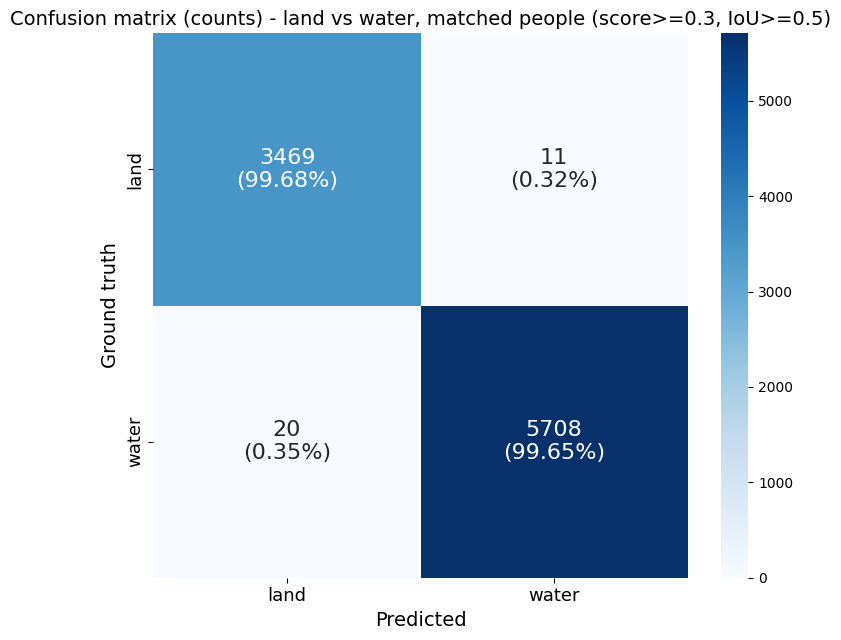

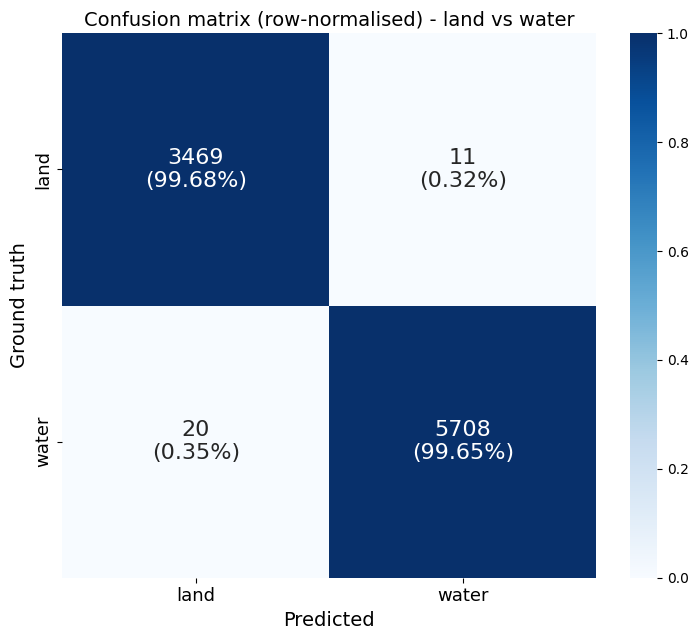

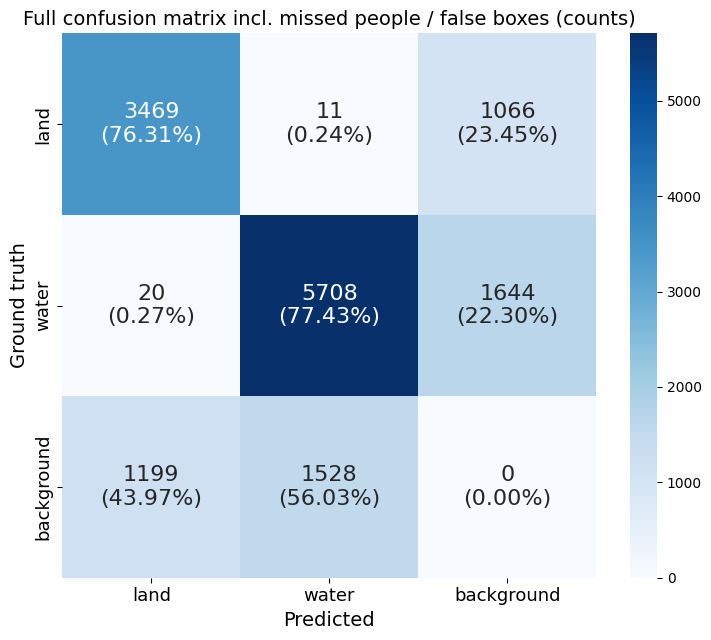

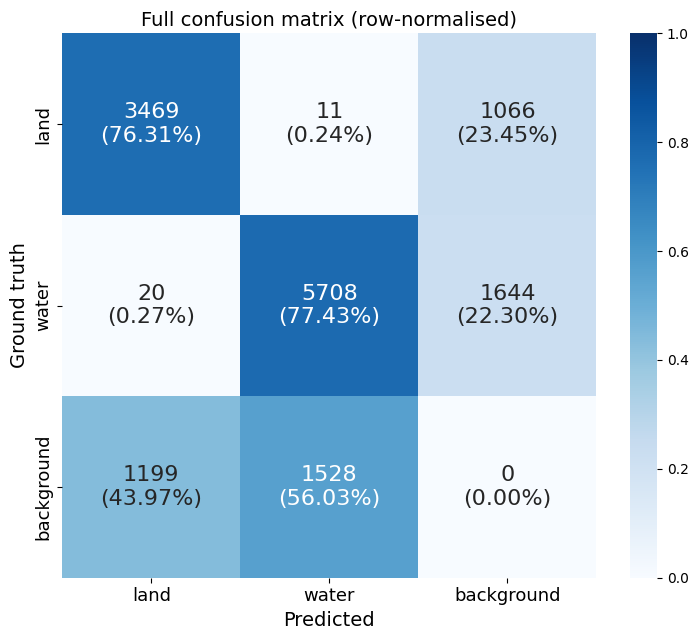

land   precision=74.00%  recall(sensitivity)=76.31%  F1=75.14%  mean IoU=82.49%  (GT people: 4546)
water  precision=78.76%  recall(sensitivity)=77.43%  F1=78.09%  mean IoU=74.00%  (GT people: 7372)
weighted F1: 76.96%
missed people (GT but no box): 2710 | false boxes (box but no GT person): 2727 | land<->water mix-ups: 31


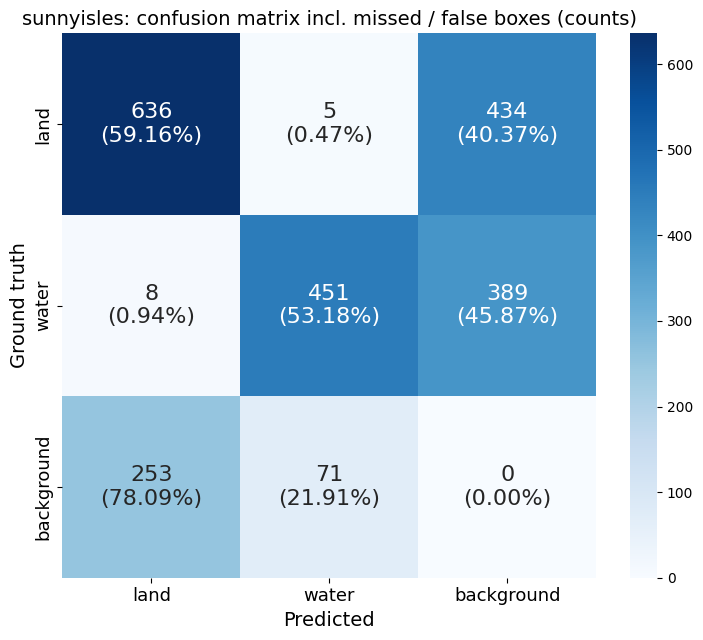

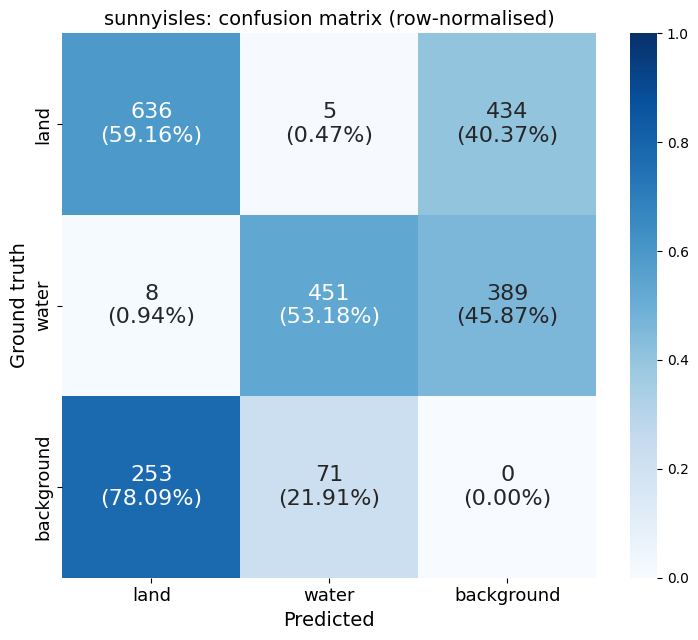

sunnyisles land   precision=70.90%  recall=59.16%  F1=64.50%
sunnyisles water  precision=85.58%  recall=53.18%  F1=65.60%


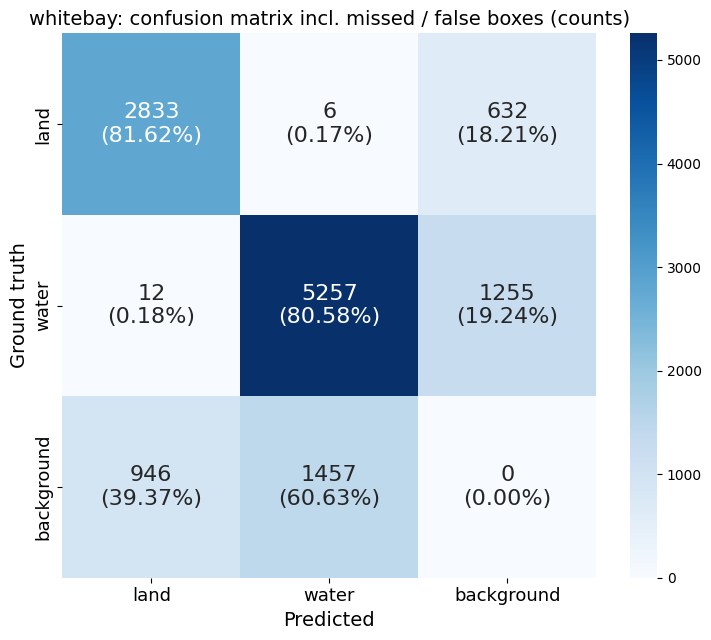

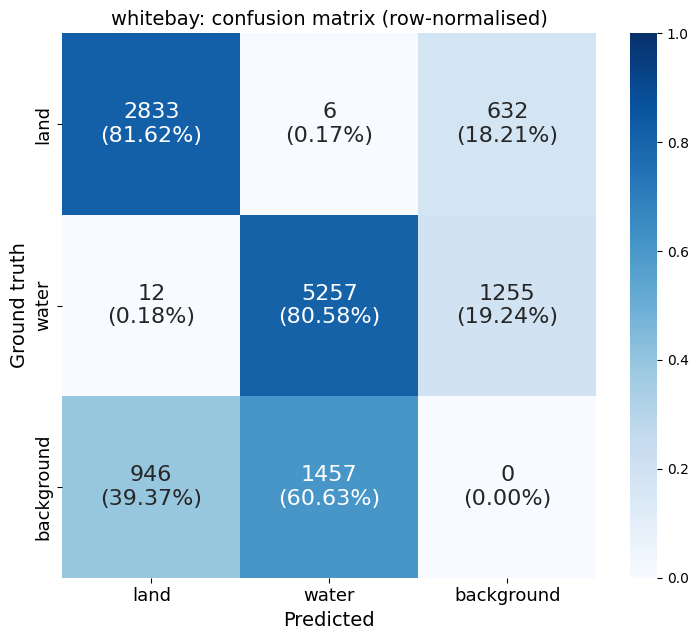

whitebay   land   precision=74.73%  recall=81.62%  F1=78.02%
whitebay   water  precision=78.23%  recall=80.58%  F1=79.39%


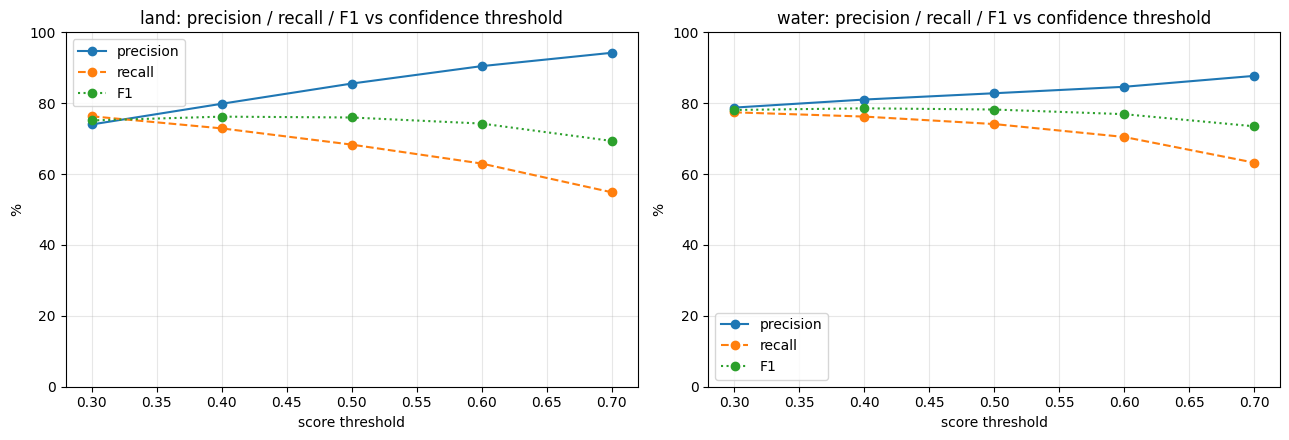

In [10]:
# ---------------- confusion matrix (raw + normalised) and per-class precision / recall / F1 / IoU ----------------
import seaborn as sns
def iou_mat(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1]); ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None); aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); bb = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + bb[None, :] - inter + 1e-9)
gt_boxes = collections.defaultdict(list)
for a in gt.dataset['annotations']:
    if a.get('iscrowd'): continue                                       # 15 px rule
    x, y, w, h = a['bbox']; gt_boxes[a['image_id']].append((x, y, x + w, y + h, a['category_id']))
def confusion(thr=SCORE_THR, iou_thr=IOU_THR, img_ids=None, P=None):
    P = preds if P is None else P
    cm = np.zeros((3, 3), dtype=int); ious = {0: [], 1: []}                 # rows: true land/water/background ; cols: predicted land/water/background
    for iid in (img_ids if img_ids is not None else [d['image_id'] for d in test_dicts]):
        G = np.array([g[:4] for g in gt_boxes[iid]], dtype=float).reshape(-1, 4); gc = [g[4] for g in gt_boxes[iid]]
        b, s, c = P[iid]; keep = s >= thr; b, s, c = b[keep], s[keep], c[keep]; order = np.argsort(-s); b, c = b[order], c[order]
        used = set(); M = iou_mat(b, G) if len(b) and len(G) else np.zeros((len(b), len(G)))
        for i in range(len(b)):
            j = -1; best = iou_thr
            for jj in range(len(G)):
                if jj not in used and M[i, jj] >= best: best = M[i, jj]; j = jj
            if j >= 0: used.add(j); cm[gc[j], c[i]] += 1; ious[gc[j]].append(M[i, j])
            else: cm[2, c[i]] += 1                                            # false positive (predicted a person where GT has none)
        for j in range(len(G)):
            if j not in used: cm[gc[j], 2] += 1                               # missed person
    return cm, ious
def prf(cm, ious):
    out = {}
    for k, n in enumerate(NAMES):
        tp = cm[k, k]; fp = cm[:, k].sum() - tp; fn = cm[k, :].sum() - tp
        p = tp / (tp + fp) if tp + fp else 0.0; r = tp / (tp + fn) if tp + fn else 0.0; f = 2 * p * r / (p + r) if p + r else 0.0
        out[n] = dict(precision=100 * p, recall=100 * r, f1=100 * f, mean_iou=100 * (np.mean(ious[k]) if ious[k] else 0.0), support=int(cm[k, :].sum()))
    tot = sum(o['support'] for o in out.values()); out['weighted_F1'] = sum(o['f1'] * o['support'] for o in out.values() if isinstance(o, dict)) / max(tot, 1)
    return out
def heat(mat, labels_r, labels_c, title, fname, normalise):
    fig, ax = plt.subplots(figsize=(7.5, 6.5)); denom = mat.sum(axis=1, keepdims=True).astype(float); denom[denom == 0] = 1
    pct = 100 * mat / denom; ann = np.array([[f'{mat[i, j]}\n({pct[i, j]:.2f}%)' for j in range(mat.shape[1])] for i in range(mat.shape[0])])
    sns.heatmap(pct / 100 if normalise else mat, annot=ann, fmt='', cmap='Blues', cbar=True, xticklabels=labels_c, yticklabels=labels_r, annot_kws={'size': 16}, ax=ax, vmin=0, vmax=1 if normalise else None)
    ax.set_xlabel('Predicted', fontsize=14); ax.set_ylabel('Ground truth', fontsize=14); ax.set_title(title, fontsize=14); ax.tick_params(labelsize=13)
    plt.tight_layout(); plt.savefig(os.path.join(OUT, fname), dpi=220); plt.show()
cm, ious = confusion(); stats = prf(cm, ious)
heat(cm[:2, :2], NAMES, NAMES, f'Confusion matrix (counts) - land vs water, matched people (score>={SCORE_THR}, IoU>={IOU_THR})', '02_confusion_raw_2x2.png', False)
heat(cm[:2, :2], NAMES, NAMES, 'Confusion matrix (row-normalised) - land vs water', '03_confusion_normalised_2x2.png', True)
heat(cm, NAMES + ['background'], NAMES + ['background'], 'Full confusion matrix incl. missed people / false boxes (counts)', '04_confusion_full_3x3.png', False)
heat(cm, NAMES + ['background'], NAMES + ['background'], 'Full confusion matrix (row-normalised)', '05_confusion_full_3x3_normalised.png', True)
for n in NAMES: print(f"{n:6s} precision={stats[n]['precision']:.2f}%  recall(sensitivity)={stats[n]['recall']:.2f}%  F1={stats[n]['f1']:.2f}%  mean IoU={stats[n]['mean_iou']:.2f}%  (GT people: {stats[n]['support']})")
print('weighted F1: %.2f%%' % stats['weighted_F1'])
print('missed people (GT but no box):', cm[0, 2] + cm[1, 2], '| false boxes (box but no GT person):', cm[2, 0] + cm[2, 1], '| land<->water mix-ups:', cm[0, 1] + cm[1, 0])
sweep = []
for thr in (0.3, 0.4, 0.5, 0.6, 0.7):
    c_, i_ = confusion(thr); s_ = prf(c_, i_); sweep.append([thr] + [round(s_[n][m], 2) for n in NAMES for m in ('precision', 'recall', 'f1')])
with open(os.path.join(OUT, 'threshold_sweep.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['score_thr'] + [f'{n}_{m}' for n in NAMES for m in ('precision', 'recall', 'f1')]); w.writerows(sweep)
json.dump({'confusion_3x3_rows_true_cols_pred_land_water_bg': cm.tolist(), 'per_class': stats}, open(os.path.join(OUT, 'metrics_confusion.json'), 'w'), indent=2)
# per-beach confusion matrices
per_beach = {}
for bch, ids in sorted(beach_ids.items()):
    cb, ib = confusion(img_ids=ids); per_beach[bch] = {'confusion_3x3': cb.tolist(), 'per_class': prf(cb, ib)}
    heat(cb, NAMES + ['background'], NAMES + ['background'], f'{bch}: confusion matrix incl. missed / false boxes (counts)', f'02b_confusion_{bch}.png', False)
    heat(cb, NAMES + ['background'], NAMES + ['background'], f'{bch}: confusion matrix (row-normalised)', f'02c_confusion_{bch}_normalised.png', True)
    for n in NAMES: print(f"{bch:10s} {n:6s} precision={per_beach[bch]['per_class'][n]['precision']:.2f}%  recall={per_beach[bch]['per_class'][n]['recall']:.2f}%  F1={per_beach[bch]['per_class'][n]['f1']:.2f}%")
json.dump(per_beach, open(os.path.join(OUT, 'metrics_per_beach.json'), 'w'), indent=2)
# precision / recall / F1 against the confidence threshold (picture of threshold_sweep.csv)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5)); th = [r[0] for r in sweep]
for k, n in enumerate(NAMES):
    for m, (lab, ls) in enumerate((('precision', '-'), ('recall', '--'), ('F1', ':'))): ax[k].plot(th, [r[1 + 3 * k + m] for r in sweep], ls, marker='o', label=lab)
    ax[k].set_title(f'{n}: precision / recall / F1 vs confidence threshold'); ax[k].set_xlabel('score threshold'); ax[k].set_ylabel('%'); ax[k].set_ylim(0, 100); ax[k].grid(alpha=.3); ax[k].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT, '06b_threshold_sweep.png'), dpi=200); plt.show()

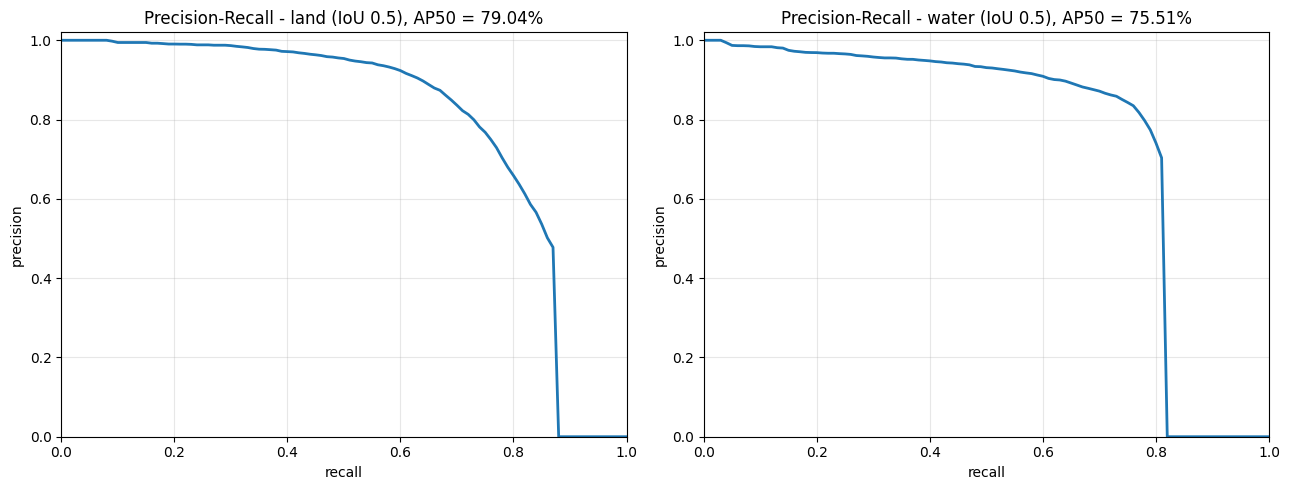

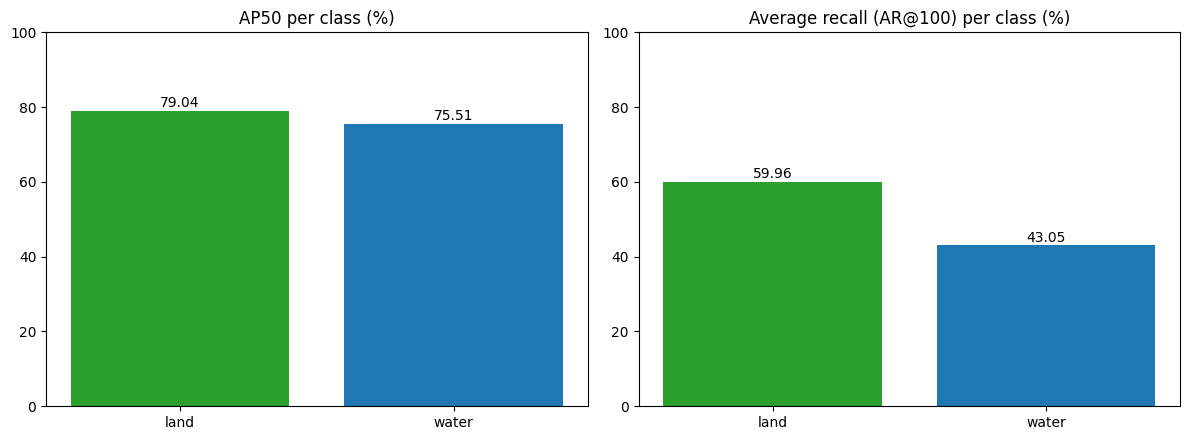

In [11]:
# ---------------- PR curves, per-class AP/AR bars ----------------
P = E_all.eval['precision']; rec = np.linspace(0, 1, 101)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, n in enumerate(NAMES):
    pr = P[0, :, k, 0, 2]; ax[k].plot(rec, np.where(pr > -1, pr, 0), lw=2); ax[k].set_xlim(0, 1); ax[k].set_ylim(0, 1.02)
    ax[k].set_title(f'Precision-Recall - {n} (IoU 0.5), AP50 = {res["AP50 " + n]:.2f}%'); ax[k].set_xlabel('recall'); ax[k].set_ylabel('precision'); ax[k].grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '06_pr_curves.png'), dpi=200); plt.show()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5)); x = np.arange(2)
ax[0].bar(x, [res['AP50 land'], res['AP50 water']], color=['#2ca02c', '#1f77b4']); ax[0].set_xticks(x); ax[0].set_xticklabels(NAMES); ax[0].set_ylim(0, 100); ax[0].set_title('AP50 per class (%)')
ax[1].bar(x, [res['AR land'], res['AR water']], color=['#2ca02c', '#1f77b4']); ax[1].set_xticks(x); ax[1].set_xticklabels(NAMES); ax[1].set_ylim(0, 100); ax[1].set_title('Average recall (AR@100) per class (%)')
for a in ax:
    for rect in a.patches: a.text(rect.get_x() + rect.get_width() / 2, rect.get_height() + 1, f'{rect.get_height():.2f}', ha='center')
plt.tight_layout(); plt.savefig(os.path.join(OUT, '07_per_class_ap_ar.png'), dpi=200); plt.show()

group | frames | AP50 | land_recall | water_recall | land_precision | water_precision | GT_land | pred_land | GT_water | pred_water
source: sunnyisles | 199 | 60.55 | 59.16 | 53.18 | 70.9 | 85.58 | 1075 | 897 | 848 | 527
source: whitebay | 200 | 80.79 | 81.62 | 80.58 | 74.73 | 78.23 | 3471 | 3791 | 6524 | 6720
crowd: sparse | 143 | 78.92 | 77.29 | 80.09 | 72.49 | 77.81 | 1418 | 1512 | 2356 | 2425
crowd: moderate | 137 | 77.27 | 76.16 | 76.36 | 73.84 | 79.56 | 1464 | 1510 | 2437 | 2339
crowd: heavy | 119 | 75.75 | 75.6 | 76.0 | 75.51 | 78.94 | 1664 | 1666 | 2579 | 2483


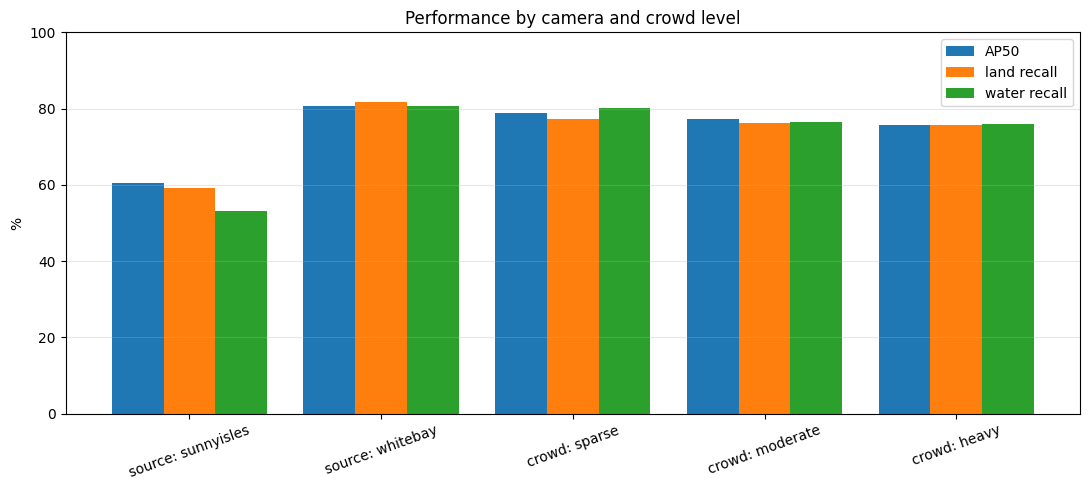

In [12]:
# ---------------- results by scenario: camera source and crowd level (sparse / moderate / heavy) ----------------
meta = {}
mp = [p for p in glob.glob(os.path.join(ROOT, '..', '*meta*.csv')) + glob.glob(os.path.join(ROOT, '*meta*.csv'))]
if mp:
    for r in csv.DictReader(open(mp[0])): meta[r['file_name']] = r.get('crowd_level')
by_id = {d['image_id']: d for d in test_dicts}
gcount = {i: sum(1 for g in gt_boxes[i]) for i in by_id}
src_of = {i: os.path.basename(by_id[i]['file_name']).split('_')[0] for i in by_id}
if not meta:
    for s_ in set(src_of.values()):
        ids = [i for i in by_id if src_of[i] == s_]; v = [gcount[i] for i in ids]; lo, hi = np.percentile(v, 33), np.percentile(v, 66)
        for i in ids: meta[os.path.basename(by_id[i]['file_name'])] = 'sparse' if gcount[i] <= lo else 'moderate' if gcount[i] <= hi else 'heavy'
lvl_of = {i: meta.get(os.path.basename(by_id[i]['file_name']), 'moderate') for i in by_id}
rows = []
def group_row(name, ids):
    if not ids: return
    E = coco_run(img_ids=ids); c_, i_ = confusion(img_ids=ids); s_ = prf(c_, i_)
    pc = {k: sum(int(((preds[i][1] >= SCORE_THR) & (preds[i][2] == k)).sum()) for i in ids) for k in (0, 1)}; gc = {k: sum(1 for i in ids for g in gt_boxes[i] if g[4] == k) for k in (0, 1)}
    rows.append([name, len(ids), round(100 * E.stats[1], 2), round(s_['land']['recall'], 2), round(s_['water']['recall'], 2), round(s_['land']['precision'], 2), round(s_['water']['precision'], 2), gc[0], pc[0], gc[1], pc[1]])
for s_ in sorted(set(src_of.values())): group_row('source: ' + s_, [i for i in by_id if src_of[i] == s_])
for l_ in ('sparse', 'moderate', 'heavy'): group_row('crowd: ' + l_, [i for i in by_id if lvl_of[i] == l_])
hdr = ['group', 'frames', 'AP50', 'land_recall', 'water_recall', 'land_precision', 'water_precision', 'GT_land', 'pred_land', 'GT_water', 'pred_water']
with open(os.path.join(OUT, 'scenario_results.csv'), 'w', newline='') as f: w = csv.writer(f); w.writerow(hdr); w.writerows(rows)
print(' | '.join(hdr))
for r in rows: print(' | '.join(str(x) for x in r))
fig, ax = plt.subplots(figsize=(11, 5)); x = np.arange(len(rows)); wd = 0.27
ax.bar(x - wd, [r[2] for r in rows], wd, label='AP50'); ax.bar(x, [r[3] for r in rows], wd, label='land recall'); ax.bar(x + wd, [r[4] for r in rows], wd, label='water recall')
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows], rotation=20); ax.set_ylim(0, 100); ax.set_ylabel('%'); ax.set_title('Performance by camera and crowd level'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '08_scenario_results.png'), dpi=200); plt.show()

## Algorithms with and without (what mam asked for: "analysis with and without")
Each variant is applied to the **same test frames** and scored with the same metrics, so every difference is measurable.
1. **Baseline** - raw frames.
2. **Denoising** (bilateral filter) - removes sensor / compression noise while keeping edges. Mam said denoising is not a major issue, so this tests that claim.
3. **CLAHE** (contrast-limited adaptive histogram equalisation on the lightness channel) - helps people against glare and bright sand.
4. **Denoise + CLAHE** combined.
5. **NMS tuning** - how strongly overlapping boxes are merged (0.3 / 0.5 / 0.7): matters in crowds.
6. **Transfer learning** - this fine-tuned model vs the original COCO model with no fine-tuning (person boxes assigned land/water by the waterline).

Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=6.89s).
Accumulating evaluation results...
DONE (t=0.21s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=6.55s).
Accumulating evaluation results...
DONE (t=0.19s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=6.65s).
Accumulating evaluation results...
DONE (t=0.22s).
Loading and preparing results...
DONE (t=0.31s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=7.01s).
Accumulating evaluation results...
DONE (t=0.21s).
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t

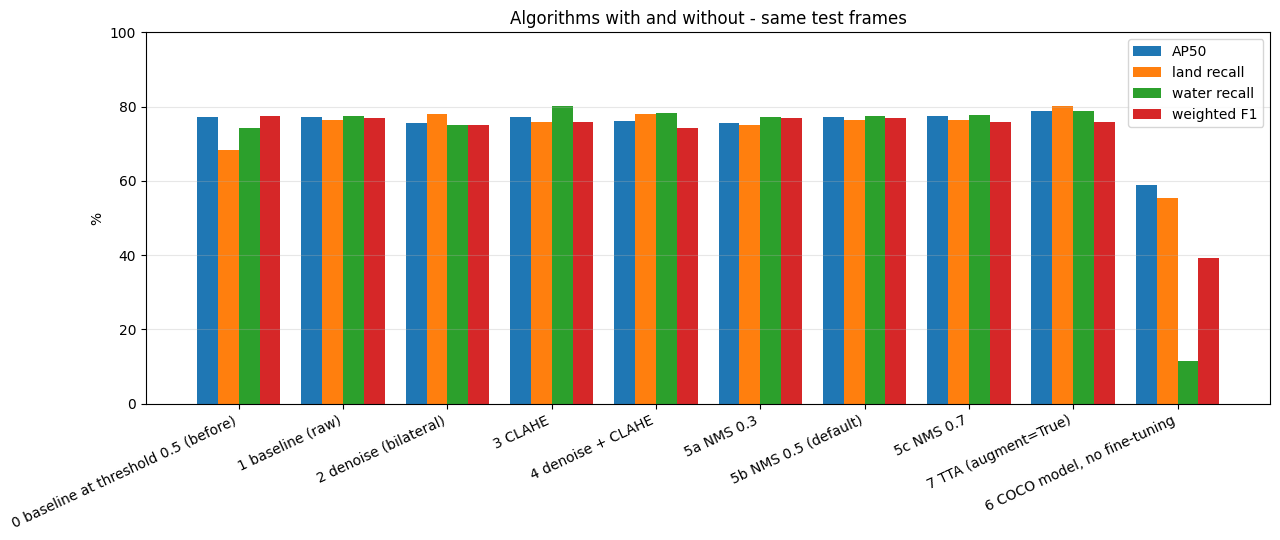

algorithm comparison saved


In [13]:
# ---------------- algorithm comparison ----------------
COL_ = {0: (0, 200, 0), 1: (255, 140, 0)}      # BGR: land = green, water = blue
def denoise(im): return cv2.bilateralFilter(im, 9, 50, 50)
def clahe(im):
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB); l, a, b = cv2.split(lab); l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge([l, a, b]), cv2.COLOR_LAB2BGR)
def both(im): return clahe(denoise(im))
def predict_all(fn=None, nms=None):
    if nms is not None: predictor.model.roi_heads.box_predictor.test_nms_thresh = nms
    P = {}
    for d in test_dicts:
        im = cv2.imread(d['file_name']); im = fn(im) if fn else im; inst = predictor(im)['instances'].to('cpu')
        P[d['image_id']] = arrs(inst)
    predictor.model.roi_heads.box_predictor.test_nms_thresh = 0.5
    return P
def score(P, thr=None):
    dl = [{'image_id': i, 'category_id': int(c), 'bbox': [float(b[0]), float(b[1]), float(b[2] - b[0]), float(b[3] - b[1])], 'score': float(s)} for i, (bb, ss, cc) in P.items() for b, s, c in zip(bb, ss, cc)]
    ap = 100 * COCOeval_stats(dl)
    cm_, io_ = confusion(P=P) if thr is None else confusion(thr=thr, P=P); st_ = prf(cm_, io_)
    return [round(ap, 2), round(st_['land']['recall'], 2), round(st_['water']['recall'], 2), round(st_['land']['precision'], 2), round(st_['water']['precision'], 2), round(st_['weighted_F1'], 2)]
def COCOeval_stats(dl):
    if not dl: return 0.0
    E = COCOeval(gt, gt.loadRes(dl), 'bbox'); E.evaluate(); E.accumulate()
    with contextlib.redirect_stdout(io.StringIO()): E.summarize()
    return E.stats[1]
variants = [('1 baseline (raw)', predict_all()), ('2 denoise (bilateral)', predict_all(denoise)), ('3 CLAHE', predict_all(clahe)), ('4 denoise + CLAHE', predict_all(both)),
            ('5a NMS 0.3', predict_all(None, 0.3)), ('5b NMS 0.5 (default)', predict_all(None, 0.5)), ('5c NMS 0.7', predict_all(None, 0.7))]
# 7 test-time augmentation (TTA: flips + scales, Ultralytics augment=True)
predictor.augment = True
try: variants.append(('7 TTA (augment=True)', predict_all()))
except Exception as e: print('TTA not supported for this model:', str(e)[:100])
predictor.augment = False
# 6 transfer learning: original COCO detector, no fine-tuning; person -> land/water by waterline (needs waterlines.json from the frames dataset)
wl = [p for p in glob.glob('/kaggle/input/**/waterlines.json', recursive=True)]
if wl:
    import cv2 as _cv
    WL = json.load(open(wl[0])); zs = UPred(PRETRAINED); P0 = {}
    def pip(pt, poly):
        x, y = pt; ins = False
        for i in range(len(poly)):
            x1, y1 = poly[i]; x2, y2 = poly[(i + 1) % len(poly)]
            if (y1 > y) != (y2 > y) and x < (x2 - x1) * (y - y1) / (y2 - y1 + 1e-9) + x1: ins = not ins
        return ins
    for d in test_dicts:
        inst = zs(cv2.imread(d['file_name']))['instances'].to('cpu'); k = inst.pred_classes.numpy() == 0; b = inst.pred_boxes.tensor.numpy()[k]; s = inst.scores.numpy()[k]; hk = (b[:, 3] - b[:, 1]) >= MIN_H; b, s = b[hk], s[hk]
        poly = WL.get(os.path.basename(d['file_name']).split('_')[0], {}).get('water_polygon', [])
        c = np.array([1 if poly and pip(((x1 + x2) / 2, y2), poly) else 0 for x1, y1, x2, y2 in b], dtype=int); P0[d['image_id']] = (b, s, c)
    variants.append(('6 COCO model, no fine-tuning', P0))
hdr = ['variant', 'AP50', 'land_recall', 'water_recall', 'land_precision', 'water_precision', 'weighted_F1']
rows_a = [['0 baseline at threshold 0.5 (before)'] + score(variants[0][1], 0.5)] + [[n] + score(P) for n, P in variants]
with open(os.path.join(OUT, 'algorithm_comparison.csv'), 'w', newline='') as f: w = csv.writer(f); w.writerow(hdr); w.writerows(rows_a)
print(' | '.join(hdr))
for r in rows_a: print(' | '.join(str(x) for x in r))
fig, ax = plt.subplots(figsize=(13, 5.5)); x = np.arange(len(rows_a)); wd = 0.2
for k, (lab, col) in enumerate((('AP50', 1), ('land recall', 2), ('water recall', 3), ('weighted F1', 6))): ax.bar(x + (k - 1.5) * wd, [r[col] for r in rows_a], wd, label=lab)
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows_a], rotation=25, ha='right'); ax.set_ylim(0, 100); ax.set_ylabel('%'); ax.set_title('Algorithms with and without - same test frames'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '09_algorithm_comparison.png'), dpi=200); plt.show()
# 3-panel pictures: original | processed | detection output (for the first 3 test frames)
for d in test_dicts[:3]:
    im = cv2.imread(d['file_name']); panels = []
    for lab, fn in (('original', None), ('denoised', denoise), ('CLAHE', clahe)):
        pim = fn(im) if fn else im.copy(); inst = predictor(pim)['instances'].to('cpu'); k = inst.scores.numpy() >= SCORE_THR; out = pim.copy()
        for (x1, y1, x2, y2), c in zip(inst.pred_boxes.tensor.numpy()[k], inst.pred_classes.numpy()[k]): cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), COL_[int(c)], 2)
        cv2.putText(out, lab, (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (255, 255, 255), 3); panels.append(cv2.resize(np.hstack([pim, out]), None, fx=0.35, fy=0.35))
    cv2.imwrite(os.path.join(OUT, f'10_three_panel_{os.path.basename(d["file_name"])[:-4]}.jpg'), np.vstack(panels))
print('algorithm comparison saved')

sunnyisles {'frames': 199.0, 'GT_land_avg': 5.4, 'pred_land_avg': 4.51, 'GT_water_avg': 4.26, 'pred_water_avg': 2.65, 'MAE_land': 1.27, 'MAE_water': 1.76}
whitebay {'frames': 200.0, 'GT_land_avg': 17.36, 'pred_land_avg': 18.95, 'GT_water_avg': 32.62, 'pred_water_avg': 33.6, 'MAE_land': 2.06, 'MAE_water': 2.82}


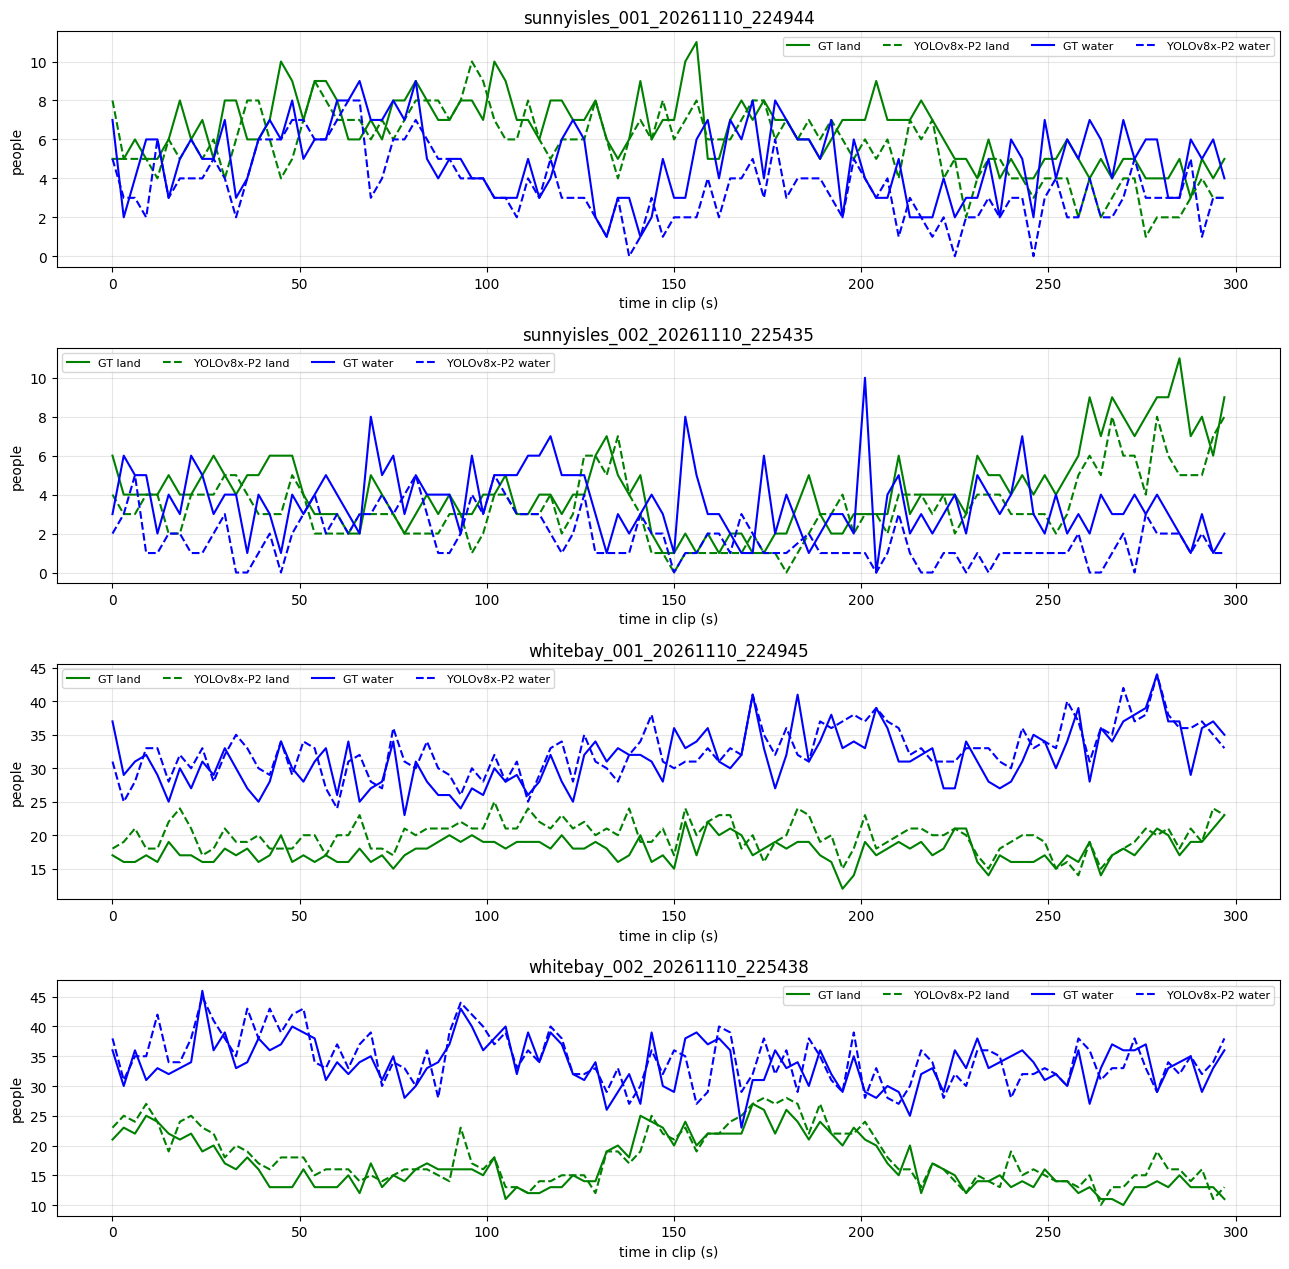

In [14]:
# ---------------- land / water COUNTS per test frame: ground truth vs YOLOv8x-P2 ----------------
import re
def clip_frame(fn):
    m = re.match(r'(.+?_\d{8}_\d{6})_f(\d+)', os.path.basename(fn)); return (m.group(1), int(m.group(2))) if m else (os.path.basename(fn), 0)
clips = collections.defaultdict(list)
for d in test_dicts: c_, n_ = clip_frame(d['file_name']); clips[c_].append((n_, d))
for c_ in clips: clips[c_].sort(key=lambda t: t[0])
crow = []
for c_, items in sorted(clips.items()):
    for n_, d in items:
        g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        crow.append([c_, n_, (n_ - 1) * 3, sum(1 for x in g if x[4] == 0), sum(1 for x in g if x[4] == 1), int((c[k] == 0).sum()), int((c[k] == 1).sum())])
with open(os.path.join(OUT, 'counts_per_frame.csv'), 'w', newline='') as f:
    w = csv.writer(f); w.writerow(['clip', 'frame', 'time_s', 'GT_land', 'GT_water', 'pred_land', 'pred_water']); w.writerows(crow)
cnt = {}
for bch in sorted(beach_ids):
    r_ = [r for r in crow if r[0].startswith(bch)]
    cnt[bch] = {'frames': len(r_), 'GT_land_avg': np.mean([r[3] for r in r_]), 'pred_land_avg': np.mean([r[5] for r in r_]), 'GT_water_avg': np.mean([r[4] for r in r_]), 'pred_water_avg': np.mean([r[6] for r in r_]),
                'MAE_land': np.mean([abs(r[3] - r[5]) for r in r_]), 'MAE_water': np.mean([abs(r[4] - r[6]) for r in r_])}
    print(bch, {k: round(float(v), 2) for k, v in cnt[bch].items()})
json.dump({b: {k: float(v) for k, v in d.items()} for b, d in cnt.items()}, open(os.path.join(OUT, 'counts_summary.json'), 'w'), indent=2)
fig, ax = plt.subplots(len(clips), 1, figsize=(13, 3.2 * len(clips)), squeeze=False)
for a, (c_, items) in zip(ax[:, 0], sorted(clips.items())):
    r_ = [r for r in crow if r[0] == c_]; t = [r[2] for r in r_]
    a.plot(t, [r[3] for r in r_], 'g-', label='GT land'); a.plot(t, [r[5] for r in r_], 'g--', label='YOLOv8x-P2 land')
    a.plot(t, [r[4] for r in r_], 'b-', label='GT water'); a.plot(t, [r[6] for r in r_], 'b--', label='YOLOv8x-P2 water')
    a.set_title(c_); a.set_xlabel('time in clip (s)'); a.set_ylabel('people'); a.grid(alpha=.3); a.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT, '11_counts_over_time.png'), dpi=170); plt.show()

In [15]:
# ---------------- VIDEO per test clip: LEFT = ground truth, RIGHT = YOLOv8x-P2 (land green, water blue, counts on top) ----------------
COL = {0: (0, 200, 0), 1: (255, 140, 0)}      # BGR: land = green, water = blue
import subprocess
def to_h264(p):                                # OpenCV writes mp4v, which browsers/Kaggle cannot play -> re-encode to H.264 (small + plays everywhere)
    t = p[:-4] + '_tmp.mp4'; os.replace(p, t)
    try: ok = subprocess.run(['ffmpeg', '-y', '-loglevel', 'error', '-i', t, '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-crf', '26', '-preset', 'veryfast', '-movflags', '+faststart', p]).returncode == 0
    except Exception: ok = False                                     # no ffmpeg -> keep the mp4v file
    if ok: os.remove(t)
    else: os.replace(t, p); print('ffmpeg failed, kept mp4v version (plays in VLC):', p)
def panel(im, boxes, classes, title, scale=1280):
    h, w = im.shape[:2]; f = scale / w; im = cv2.resize(im, (scale, int(h * f)))
    n = {0: 0, 1: 0}
    for (x1, y1, x2, y2), c in zip(boxes, classes):
        n[int(c)] += 1; cv2.rectangle(im, (int(x1 * f), int(y1 * f)), (int(x2 * f), int(y2 * f)), COL[int(c)], 2)
    txt = f'{title}   Land: {n[0]}  |  Water: {n[1]}'; (tw, th), _ = cv2.getTextSize(txt, cv2.FONT_HERSHEY_SIMPLEX, 0.9, 2)
    cv2.rectangle(im, (0, 0), (tw + 24, th + 22), (0, 0, 0), -1); cv2.putText(im, txt, (12, th + 8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
    return im
allw = None
for c_, items in sorted(clips.items()):
    vw = None
    for n_, d in items:
        im = cv2.imread(d['file_name']); g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        frame = np.hstack([panel(im.copy(), [x[:4] for x in g], [x[4] for x in g], 'Ground truth'), panel(im.copy(), b[k], c[k], 'YOLOv8x-P2')])
        cv2.putText(frame, f'{c_}  frame {n_}  (t = {(n_ - 1) * 3} s)', (12, frame.shape[0] - 14), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2, cv2.LINE_AA)
        if vw is None: vw = cv2.VideoWriter(os.path.join(OUT, f'video_GT_vs_YOLOv8x-P2_{c_}.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), VIDEO_FPS, (frame.shape[1], frame.shape[0]))
        if allw is None: allw = cv2.VideoWriter(os.path.join(OUT, 'video_GT_vs_YOLOv8x-P2_ALL_test_clips.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), VIDEO_FPS, (frame.shape[1], frame.shape[0]))
        vw.write(frame); allw.write(frame)
    vw.release(); to_h264(os.path.join(OUT, f'video_GT_vs_YOLOv8x-P2_{c_}.mp4')); print('saved video_GT_vs_YOLOv8x-P2_%s.mp4 (%d frames)' % (c_, len(items)))
allw.release(); to_h264(os.path.join(OUT, 'video_GT_vs_YOLOv8x-P2_ALL_test_clips.mp4'))
# still pictures for the report / slides: the 3 most crowded test frames of each beach, GT left vs YOLOv8x-P2 right
for bch in sorted(beach_ids):
    top = sorted([d for d in test_dicts if beach_of(d['file_name']) == bch], key=lambda d: -len(gt_boxes[d['image_id']]))[:3]
    for j, d in enumerate(top):
        im = cv2.imread(d['file_name']); g = gt_boxes[d['image_id']]; b, s, c = preds[d['image_id']]; k = s >= SCORE_THR
        cv2.imwrite(os.path.join(OUT, f'12_sample_{bch}_{j + 1}_GT_vs_YOLOv8x-P2.jpg'),
                    np.hstack([panel(im.copy(), [x[:4] for x in g], [x[4] for x in g], 'Ground truth'), panel(im.copy(), b[k], c[k], 'YOLOv8x-P2')]))
print('sample pictures saved (12_sample_*.jpg)')

saved video_GT_vs_YOLOv8x-P2_sunnyisles_001_20261110_224944.mp4 (100 frames)
saved video_GT_vs_YOLOv8x-P2_sunnyisles_002_20261110_225435.mp4 (99 frames)
saved video_GT_vs_YOLOv8x-P2_whitebay_001_20261110_224945.mp4 (100 frames)
saved video_GT_vs_YOLOv8x-P2_whitebay_002_20261110_225438.mp4 (100 frames)
sample pictures saved (12_sample_*.jpg)


In [16]:
# ---------------- CONTINUOUS real-speed video of each test clip (needs the clip videos attached as an input) ----------------
VID = {}
for dp, dn, fn in os.walk('/kaggle/input'):
    for f in fn:
        if f.lower().endswith(('.mkv', '.mp4', '.avi', '.mov')): VID[os.path.splitext(f)[0]] = os.path.join(dp, f)
cont = []
for c_ in sorted(clips):
    if c_ not in VID: print('no video file for', c_, '-> skipped (attach the clip videos to make this)'); continue
    bch = c_.split('_')[0]; cap = cv2.VideoCapture(VID[c_]); fps = cap.get(cv2.CAP_PROP_FPS) or 25
    nmax = int(CONT_SECONDS * fps) if CONT_SECONDS else int(cap.get(cv2.CAP_PROP_FRAME_COUNT)); vw = None; last = (np.zeros((0, 4)), np.zeros(0)); i = 0
    while i < nmax:
        ok, im = cap.read()
        if not ok: break
        if im.shape[1] != 1920: im = cv2.resize(im, (1920, 1080))
        for x, y, w, h in MASKS.get(bch, []): im[y:y + h, x:x + w] = 0              # same masking as the training frames
        if i % CONT_STRIDE == 0:
            b, s, c = arrs(predictor(im)['instances'].to('cpu')); k = s >= SCORE_THR; last = (b[k], c[k])
            cont.append([c_, round(i / fps, 2), int((last[1] == 0).sum()), int((last[1] == 1).sum())])
        out = panel(im, last[0], last[1], 'YOLOv8x-P2 (real speed)')
        if vw is None: vw = cv2.VideoWriter(os.path.join(OUT, f'video_continuous_{c_}.mp4'), cv2.VideoWriter_fourcc(*'mp4v'), fps, (out.shape[1], out.shape[0]))
        vw.write(out); i += 1
    vw.release(); cap.release(); to_h264(os.path.join(OUT, f'video_continuous_{c_}.mp4')); print('saved video_continuous_%s.mp4: %d frames at %.1f fps' % (c_, i, fps))
if cont:
    with open(os.path.join(OUT, 'counts_continuous.csv'), 'w', newline='') as f:
        w = csv.writer(f); w.writerow(['clip', 'time_s', 'pred_land', 'pred_water']); w.writerows(cont)

saved video_continuous_sunnyisles_001_20261110_224944.mp4: 3750 frames at 62.5 fps
saved video_continuous_sunnyisles_002_20261110_225435.mp4: 3750 frames at 62.5 fps
saved video_continuous_whitebay_001_20261110_224945.mp4: 1818 frames at 30.3 fps
saved video_continuous_whitebay_002_20261110_225438.mp4: 1818 frames at 30.3 fps


In [17]:
# ---------------- package + final summary ----------------
zp = '/kaggle/working/G110_YOLOv8xP2_Results.zip'                 # small zip: everything EXCEPT videos (download videos one by one)
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in glob.glob(os.path.join(OUT, '*')):
        if os.path.isfile(p) and not p.endswith('.mp4'): z.write(p, os.path.basename(p))
for d_ in ['/kaggle/working/coco_fixed', '/kaggle/working/coco_from_yolo'] + glob.glob('/kaggle/working/G110-Beach-People-Final-*') + glob.glob('/kaggle/working/rf_v*') + ['/kaggle/working/coco_eval']:
    shutil.rmtree(d_, ignore_errors=True)                           # dataset copies are not results -> remove so the Output tab stays small
if Y.startswith('/kaggle/working/'): shutil.rmtree(Y, ignore_errors=True)   # the downloaded dataset, whatever Roboflow named the folder
for p in sorted(glob.glob('/kaggle/working/**/*', recursive=True)):
    if os.path.isfile(p) and os.path.getsize(p) > 20e6: print('big file: %-70s %6.0f MB' % (p, os.path.getsize(p) / 1e6))
print('Dataset: Roboflow', RF_PROJECT, 'v%d' % RF_VERSION, '| model:', MODEL_KIND, '| weights:', BEST, '(download best.pt from the Output tab: runs/train/weights)')
print('mAP@50: %.2f%% | mAP@50:95: %.2f%% | speed: %.2f frames/s' % (res['mAP@50'], res['mAP@50:95'], FPS_MODEL))
print('AP50 land: %.2f%% | AP50 water: %.2f%%' % (res['AP50 land'], res['AP50 water']))
print('Recall land: %.2f%% | Recall water: %.2f%%' % (stats['land']['recall'], stats['water']['recall']))
for bch in sorted(beach_ids): print('%-10s mAP@50: %.2f%% | count error per frame (MAE) land %.2f, water %.2f' % (bch, res[bch + ' mAP@50'], cnt[bch]['MAE_land'], cnt[bch]['MAE_water']))
print('All outputs zipped ->', zp)

big file: /kaggle/working/outputs/video_GT_vs_YOLOv8x-P2_ALL_test_clips.mp4          48 MB
big file: /kaggle/working/runs/train/weights/best.pt                                134 MB
big file: /kaggle/working/runs/train/weights/last.pt                                134 MB
big file: /kaggle/working/yolov8x.pt                                                137 MB
Dataset: Roboflow g110-beach-people-final v2 | model: yolov8x-p2 | weights: /kaggle/working/runs/train/weights/best.pt (download best.pt from the Output tab: runs/train/weights)
mAP@50: 77.28% | mAP@50:95: 41.42% | speed: 2.58 frames/s
AP50 land: 79.04% | AP50 water: 75.51%
Recall land: 76.31% | Recall water: 77.43%
sunnyisles mAP@50: 60.55% | count error per frame (MAE) land 1.27, water 1.76
whitebay   mAP@50: 80.79% | count error per frame (MAE) land 2.06, water 2.82
All outputs zipped -> /kaggle/working/G110_YOLOv8xP2_Results.zip
